In [5]:
from pycaret.datasets import get_data
data = get_data('insurance')

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


# Experiment 1

In [6]:
from pycaret.datasets import get_data
from pycaret.regression import RegressionExperiment

In [7]:
# 2. Инициализация эксперимента
# target='charges' — предсказываем стоимость страховки
exp = RegressionExperiment(target='charges', session_id=123)
exp.fit(data)

# 3. Сравнение всех моделей (возвращает CompareResult)
compare_result = exp.compare_models()

# 4. Извлекаем лучшую модель
best_model = compare_result.best          # <-- это уже sklearn Pipeline


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000650 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 316
[LightGBM] [Info] Number of data points in the train set: 842, number of used features: 6
[LightGBM] [Info] Start training from score 13199.000997
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000520 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 315
[LightGBM] [Info] Number of data points in the train set: 842, number of used features: 6
[LightGBM] [Info] Start training from score 13346.111875
[LightGBM] [Warn

In [10]:
# 5. Создаём конкретную модель (линейная регрессия)
# create_model возвращает CreateResult
lr_result = exp.create_model('lr')



# 6. Прогноз (можно напрямую через sklearn, без exp.predict_model)
lr_model = lr_result.pipeline
X = data.drop(columns=['charges'])
predictions = lr_model.predict(X)
print(predictions[:5])

[25066.67733967  3901.46572913  7175.46317466  3876.37650735
  5741.45237584]


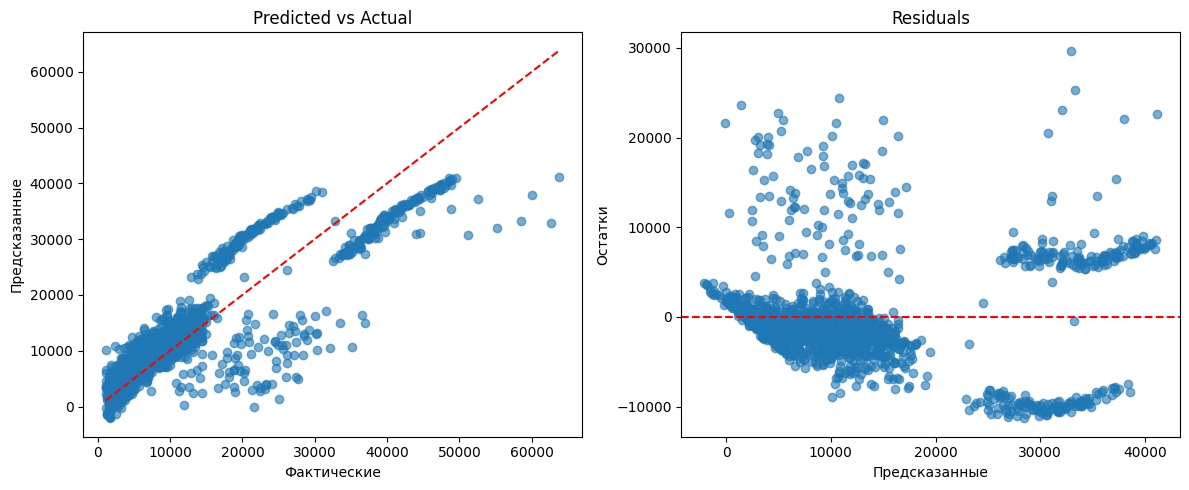

In [18]:
import matplotlib.pyplot as plt

X = data.drop(columns=['charges'])
y_true = data['charges']
y_pred = lr_model.predict(X)
residuals = y_true - y_pred

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Predicted vs Actual
axes[0].scatter(y_true, y_pred, alpha=0.6)
axes[0].plot([y_true.min(), y_true.max()],
             [y_true.min(), y_true.max()], 'r--')
axes[0].set_xlabel('Фактические')
axes[0].set_ylabel('Предсказанные')
axes[0].set_title('Predicted vs Actual')

# Residuals
axes[1].scatter(y_pred, residuals, alpha=0.6)
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_xlabel('Предсказанные')
axes[1].set_ylabel('Остатки')
axes[1].set_title('Residuals')

plt.tight_layout()
plt.show()

# Experiment 2

In [11]:
exp2 = RegressionExperiment(
    target='charges',
    session_id=123,
    normalize=True
)
exp2.fit(data)

,target,'charges'
,session_id,123
,normalize,True
,logger,<pycaret.logg...0023408B57170>
,train_size,0.7
,fold,10
,fold_strategy,'kfold'
,preprocess,True
,transformation,False
,remove_outliers,False
,feature_selection,False


In [ ]:
print(exp2.X_train.columns)

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region'], dtype='str')


In [12]:
lr_result = exp.create_model('lr')



# 6. Прогноз (можно напрямую через sklearn, без exp.predict_model)
lr_model = lr_result.pipeline
predictions = lr_model.predict(X)
print(predictions[:5])

[25066.67733967  3901.46572913  7175.46317466  3876.37650735
  5741.45237584]


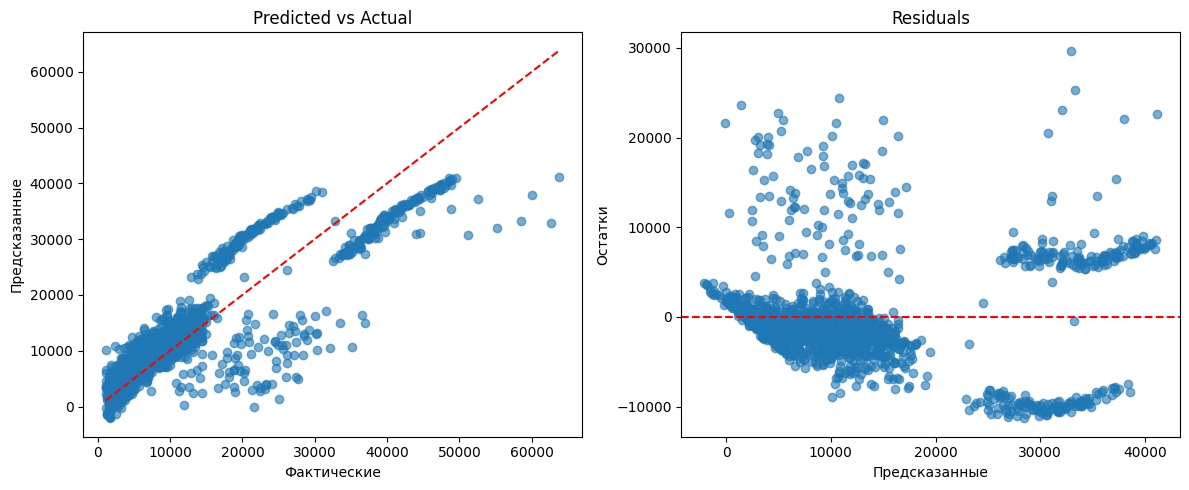

In [19]:
import matplotlib.pyplot as plt

X = data.drop(columns=['charges'])
y_true = data['charges']
y_pred = lr_model.predict(X)
residuals = y_true - y_pred

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Predicted vs Actual
axes[0].scatter(y_true, y_pred, alpha=0.6)
axes[0].plot([y_true.min(), y_true.max()],
             [y_true.min(), y_true.max()], 'r--')
axes[0].set_xlabel('Фактические')
axes[0].set_ylabel('Предсказанные')
axes[0].set_title('Predicted vs Actual')

# Residuals
axes[1].scatter(y_pred, residuals, alpha=0.6)
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_xlabel('Предсказанные')
axes[1].set_ylabel('Остатки')
axes[1].set_title('Residuals')

plt.tight_layout()
plt.show()

In [ ]:
from joblib import dump

# lr_model — это ваш пайплайн, полученный из lr_result.pipeline
dump(lr_model, "test_mode.joblib")

['test_mode.joblib']